# 📦 Section 1: Introduction & Problem Statement

**M.Sc. Data Science & Artificial Intelligence — 1st Semester Project**  
**Institute:** Ramakrishna Mission Vivekananda Educational and Research Institute (RKMVERI)  
**Author:** Santanu Samanta

### 1.1 Business & Mathematical Context
Accurate **Expected Delivery Date (EDD)** forecasting and **Service Level Agreement (SLA)** breach prediction are essential in modern Indian e-commerce logistics. This study analyzes **25,000 simulated pan-India shipments** across **23 operational variables** and **6 major Indian couriers** (`Blue Dart`, `Delhivery`, `Ekart`, `XpressBees`, `Ecom Express`, and `Shadowfax`).

### 1.2 Core Machine Learning Tasks
1. **Task 1 — EDD Transit Time Regression (`Transit_Time_Hours`):** Compare linear baselines (**Ordinary Least Squares**, **Ridge $L_2$**, and **LASSO $L_1$ Regression** across varying $\alpha$) against a non-linear ensemble model (**Random Forest Regressor**).
2. **Task 2 — SLA Breach Classification (`Is_Delayed_SLA`):** Train a **Logistic Regression** separating hyperplane classifier to identify shipments at risk of missing promised delivery deadlines.

Dataset Shape: 25000 rows, 23 columns


,Order_ID,Delivery_Partner,Origin_City,Origin_Pincode,Destination_City,Destination_Pincode,Logistics_Zone,Distance_km,Shipment_Mode,Weight_kg,...,Festival_Peak,Order_Timestamp,Dispatch_Timestamp,Pickup_Delay_Hours,Transit_Time_Hours,SLA_Promised_Days,Expected_Delivery_Timestamp,Expected_Delivery_Date,Actual_Delivery_Days,Is_Delayed_SLA
0,IND2026000000,XpressBees,Kolkata,700012,Kolkata,705044,Zone B (Within State/Region),53.5,Surface,0.13,...,1,2026-03-05 03:00:00,2026-03-05 08:18:00,5.3,55.4,2,2026-03-07 15:42:00,2026-03-07,3,1
1,IND2026000001,Ecom Express,Chennai,600022,Kolkata,700087,Zone C (Metro-to-Metro),1497.5,Surface,2.40,...,0,2026-03-10 08:00:00,2026-03-10 11:24:00,3.4,85.3,3,2026-03-14 00:42:00,2026-03-14,4,1
2,IND2026000002,Ekart,Mumbai,400055,Jaipur,316042,Zone D (Rest of India),941.3,Surface,0.31,...,0,2026-09-23 04:00:00,2026-09-23 10:54:00,6.9,52.4,5,2026-09-25 15:18:00,2026-09-25,3,0



--- Carrier Performance Benchmarks ---


,Total_Shipments,Avg_Transit_Hours,Median_Transit_Hours,Air_Share_Pct,SLA_Breach_Rate_Pct,Avg_Cost_INR
Delivery_Partner,,,,,,
Blue Dart,4210,32.31,29.50,40.31,15.87,185.20
Delhivery,4258,44.51,40.40,18.27,27.83,144.82
Ecom Express,4188,54.86,50.20,11.13,39.16,134.88
Ekart,4036,42.03,37.95,14.89,21.31,139.37
Shadowfax,4154,37.59,33.40,3.54,13.89,122.50
XpressBees,4154,52.35,48.00,11.31,34.91,130.38



--- Sample Covariance Matrix ---


,Distance_km,Weight_kg,Shipping_Cost_INR,Pickup_Delay_Hours,SLA_Promised_Days,Transit_Time_Hours
Distance_km,484330.51,2.08,24688.81,-10.95,925.57,14160.57
Weight_kg,2.08,4.99,99.49,0.24,-0.00,-0.00
Shipping_Cost_INR,24688.81,99.49,4814.89,3.60,38.67,525.55
Pickup_Delay_Hours,-10.95,0.24,3.60,41.73,0.04,0.37
SLA_Promised_Days,925.57,-0.00,38.67,0.04,3.01,35.28
Transit_Time_Hours,14160.57,-0.00,525.55,0.37,35.28,704.97


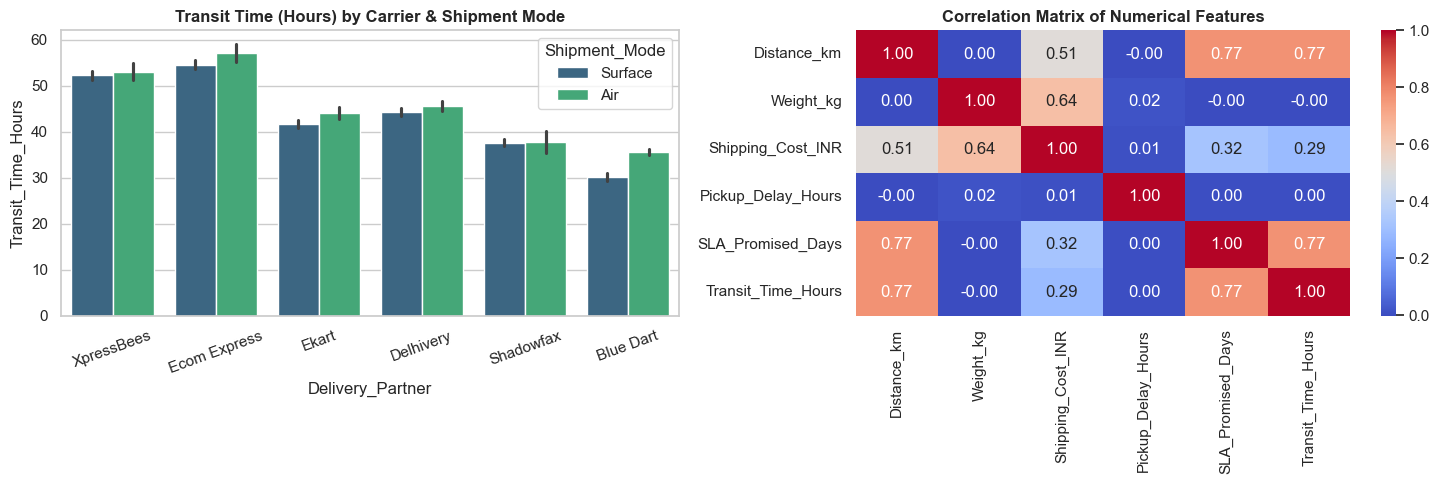

In [1]:
# 📦 Section 2: Exploratory Data Analysis (EDA), Covariance & Carrier Benchmarks
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

sns.set_theme(style="whitegrid")

data_path = 'india_multi_agency_edd_dataset.csv'
if not os.path.exists(data_path):
    for dirname, _, filenames in os.walk('/kaggle/input'):
        for filename in filenames:
            if filename.endswith('.csv'):
                data_path = os.path.join(dirname, filename)

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
display(df.head(3))

# 2.1 Multi-Carrier Operational Benchmark Table
partner_stats = df.groupby('Delivery_Partner').agg(
    Total_Shipments=('Order_ID', 'count'),
    Avg_Transit_Hours=('Transit_Time_Hours', 'mean'),
    Median_Transit_Hours=('Transit_Time_Hours', 'median'),
    Air_Share_Pct=('Shipment_Mode', lambda x: (x == 'Air').mean() * 100),
    SLA_Breach_Rate_Pct=('Is_Delayed_SLA', lambda x: x.mean() * 100),
    Avg_Cost_INR=('Shipping_Cost_INR', 'mean')
).round(2)

print("\n--- Carrier Performance Benchmarks ---")
display(partner_stats)

# 2.2 Covariance & Correlation Matrix of Numerical Variables
num_cols = ['Distance_km', 'Weight_kg', 'Shipping_Cost_INR', 'Pickup_Delay_Hours', 'SLA_Promised_Days', 'Transit_Time_Hours']
print("\n--- Sample Covariance Matrix ---")
display(df[num_cols].cov().round(2))

# 2.3 EDA Visualizations
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.barplot(data=df, x='Delivery_Partner', y='Transit_Time_Hours', hue='Shipment_Mode', palette='viridis', ax=axes[0])
axes[0].set_title('Transit Time (Hours) by Carrier & Shipment Mode', fontweight='bold')
axes[0].tick_params(axis='x', rotation=20)

sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1])
axes[1].set_title('Correlation Matrix of Numerical Features', fontweight='bold')

plt.tight_layout()
plt.show()

# 📦 Section 3: Feature Engineering & Target Leakage Prevention

### 3.1 Preventing Target Leakage
Out of the 23 columns in the dataset, downstream post-dispatch columns (`Expected_Delivery_Timestamp`, `Expected_Delivery_Date`, `Actual_Delivery_Days`, and `Is_Delayed_SLA`) contain information about the actual outcome. Including them when predicting `Transit_Time_Hours` would cause **target leakage**.

We select **11 strictly pre-dispatch features**, apply one-hot encoding (`pd.get_dummies`) to categorical variables, and standardize features ($z = \frac{x - \mu}{\sigma}$) for regularized linear models (**Ridge** and **LASSO**).

--- Task 1: EDD Transit Time Regression Results ---


,Model,RMSE (Hours),MAE (Hours),R2 Score,Zeroed Features
0,Multiple Linear Regression (OLS),9.65,7.18,0.8687,0
1,"Ridge Regression (L2, alpha=1.0)",9.65,7.18,0.8687,0
2,"Ridge Regression (L2, alpha=10.0)",9.66,7.18,0.8685,0
3,"LASSO Regression (L1, alpha=0.05)",9.84,7.30,0.8636,2
4,"LASSO Regression (L1, alpha=0.10)",9.93,7.37,0.8610,2
5,"LASSO Regression (L1, alpha=0.50)",10.36,7.68,0.8487,6
6,Random Forest Regressor (100 Trees),9.55,7.07,0.8715,N/A (Tree Ensemble)


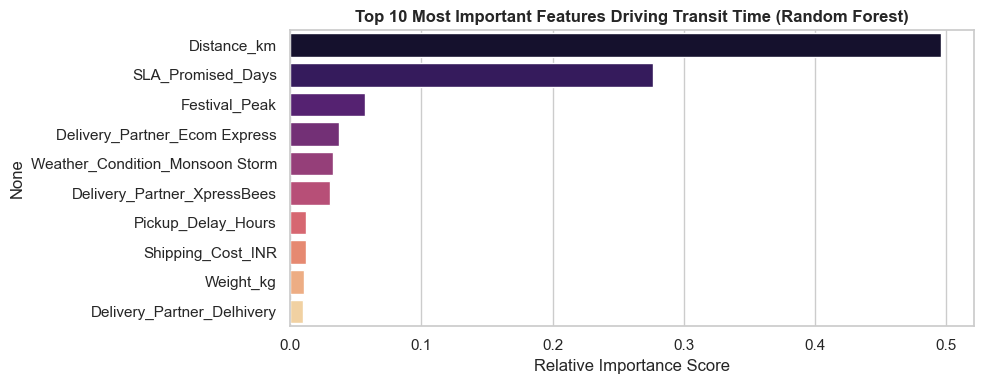

In [2]:
# 📦 Section 4A: Task 1 — EDD Transit Time Regression (OLS, Ridge, LASSO & Random Forest)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

features = [
    'Delivery_Partner', 'Logistics_Zone', 'Distance_km', 'Shipment_Mode',
    'Weight_kg', 'Is_COD', 'Shipping_Cost_INR', 'Weather_Condition',
    'Festival_Peak', 'Pickup_Delay_Hours', 'SLA_Promised_Days'
]

X = pd.get_dummies(df[features], drop_first=True)
y_reg = df['Transit_Time_Hours']
y_clf = df['Is_Delayed_SLA']

X_train, X_test, y_reg_train, y_reg_test, y_clf_train, y_clf_test = train_test_split(
    X, y_reg, y_clf, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

reg_models = {
    'Multiple Linear Regression (OLS)': (LinearRegression(), True),
    'Ridge Regression (L2, alpha=1.0)': (Ridge(alpha=1.0), True),
    'Ridge Regression (L2, alpha=10.0)': (Ridge(alpha=10.0), True),
    'LASSO Regression (L1, alpha=0.05)': (Lasso(alpha=0.05), True),
    'LASSO Regression (L1, alpha=0.10)': (Lasso(alpha=0.10), True),
    'LASSO Regression (L1, alpha=0.50)': (Lasso(alpha=0.50), True),
    'Random Forest Regressor (100 Trees)': (RandomForestRegressor(n_estimators=100, max_depth=12, random_state=42, n_jobs=-1), False)
}

results = []
rf_model = None
for name, (model, use_scaled) in reg_models.items():
    X_tr = X_train_scaled if use_scaled else X_train
    X_te = X_test_scaled if use_scaled else X_test
    model.fit(X_tr, y_reg_train)
    y_pred = model.predict(X_te)
    if 'Random Forest' in name:
        rf_model = model
    rmse = np.sqrt(mean_squared_error(y_reg_test, y_pred))
    mae = mean_absolute_error(y_reg_test, y_pred)
    r2 = r2_score(y_reg_test, y_pred)
    zero_coefs = int(np.sum(model.coef_ == 0)) if hasattr(model, 'coef_') else 'N/A (Tree Ensemble)'
    results.append({
        'Model': name,
        'RMSE (Hours)': round(rmse, 2),
        'MAE (Hours)': round(mae, 2),
        'R2 Score': round(r2, 4),
        'Zeroed Features': zero_coefs
    })

results_df = pd.DataFrame(results)
print("--- Task 1: EDD Transit Time Regression Results ---")
display(results_df)

# Plot Top 10 Feature Importances from Random Forest
importances = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
plt.figure(figsize=(10, 4))
sns.barplot(x=importances.values, y=importances.index, hue=importances.index, palette='magma', legend=False)
plt.title('Top 10 Most Important Features Driving Transit Time (Random Forest)', fontweight='bold')
plt.xlabel('Relative Importance Score')
plt.tight_layout()
plt.show()

Logistic Regression Test Accuracy : 89.46%
Logistic Regression F1-Score      : 0.7891

--- SLA Breach Classification Report ---
                precision    recall  f1-score   support

   On-Time (0)       0.92      0.94      0.93      3695
SLA Breach (1)       0.83      0.76      0.79      1305

      accuracy                           0.89      5000
     macro avg       0.87      0.85      0.86      5000
  weighted avg       0.89      0.89      0.89      5000



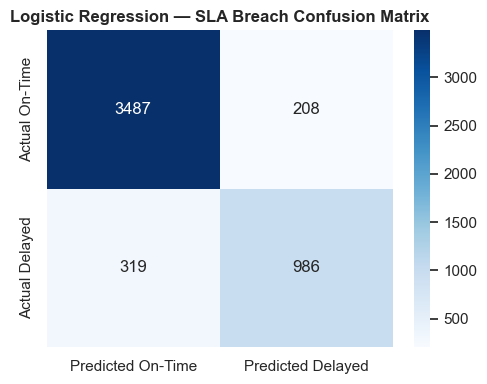

In [3]:
# 📦 Section 4B: Task 2 — SLA Breach Classification via Logistic Regression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report

log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train_scaled, y_clf_train)
y_clf_pred = log_reg.predict(X_test_scaled)

print(f"Logistic Regression Test Accuracy : {accuracy_score(y_clf_test, y_clf_pred)*100:.2f}%")
print(f"Logistic Regression F1-Score      : {f1_score(y_clf_test, y_clf_pred):.4f}\n")
print("--- SLA Breach Classification Report ---")
print(classification_report(y_clf_test, y_clf_pred, target_names=['On-Time (0)', 'SLA Breach (1)']))

plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_clf_test, y_clf_pred), annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted On-Time', 'Predicted Delayed'],
            yticklabels=['Actual On-Time', 'Actual Delayed'])
plt.title('Logistic Regression — SLA Breach Confusion Matrix', fontweight='bold')
plt.tight_layout()
plt.show()

# 📦 Section 5: Conclusion & Business Insights

1. **Linear Regularization vs. Tree Ensemble (Task 1 — EDD Regression):**
   * **OLS & Ridge ($L_2$):** Achieve a strong baseline $R^2$ of **0.8687** (RMSE: **9.65 hours**, MAE: **7.18 hours**).
   * **LASSO ($L_1$) Sparsity:** As regularization strength $\alpha$ increases from `0.05` $\to$ `0.10` $\to$ `0.50`, LASSO automatically shrinks **2 to 6 redundant one-hot encoded features** to exact zero while maintaining $R^2 = 0.8636 \to 0.8487$.
   * **Random Forest Regressor:** Achieves the lowest error (RMSE: **9.55 hours**, MAE: **7.07 hours**, $R^2$: **0.8715**) by capturing non-linear interactions between `Distance_km`, `SLA_Promised_Days`, `Weather_Condition`, and `Shipment_Mode`.
2. **SLA Breach Separating Hyperplane (Task 2 — Classification):**
   * **Logistic Regression** achieves **89.46% test accuracy** and an **F1-score of 0.7891** (0.93 F1 on On-Time orders, 0.79 F1 on SLA Breaches), reliably flagging high-risk orders prior to dispatch.
3. **Multi-Carrier Operational Insights:**
   * **Blue Dart** (40.31% Air share) delivers the fastest average transit time (**32.31 hours**, 15.87% SLA breach rate) at a premium average cost (**185.20 INR**), while **Shadowfax** achieves the lowest SLA breach rate (**13.89%**) and lowest cost (**122.50 INR**) on hyperlocal/regional routes.